# WP12 — Beş gerçek senaryolu küçük OpenAI pilotu

S01/S07/S04 açıklama; S16/S15 farklı kaynak yetersizliği retleridir. İki kullanıcı PDF’si ve seçilmiş beş soru vardır; bağımsız klinik doğrulama değildir. Yeni API, OCR, model eğitimi veya yayın yok. Resmî insan kararları PENDING.

Gerçek S15, değiştirilmeden:
{"result":{"schema_version":"WP12-local-llm-candidate-v2","language":"tr","status":"refused","refusal_code":"IMAGE_TEXT_UNAVAILABLE","items":[]}}


,0
document_id,sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5
physical_page,10
document_exists,True
image_objects,1
text_layer_codepoints,154
text_layer_role,footer_only_not_image_box_quote
image_box_extracted_text_available,False
OCR_performed,False
vision_inference_performed,False
image_sent_to_API,False


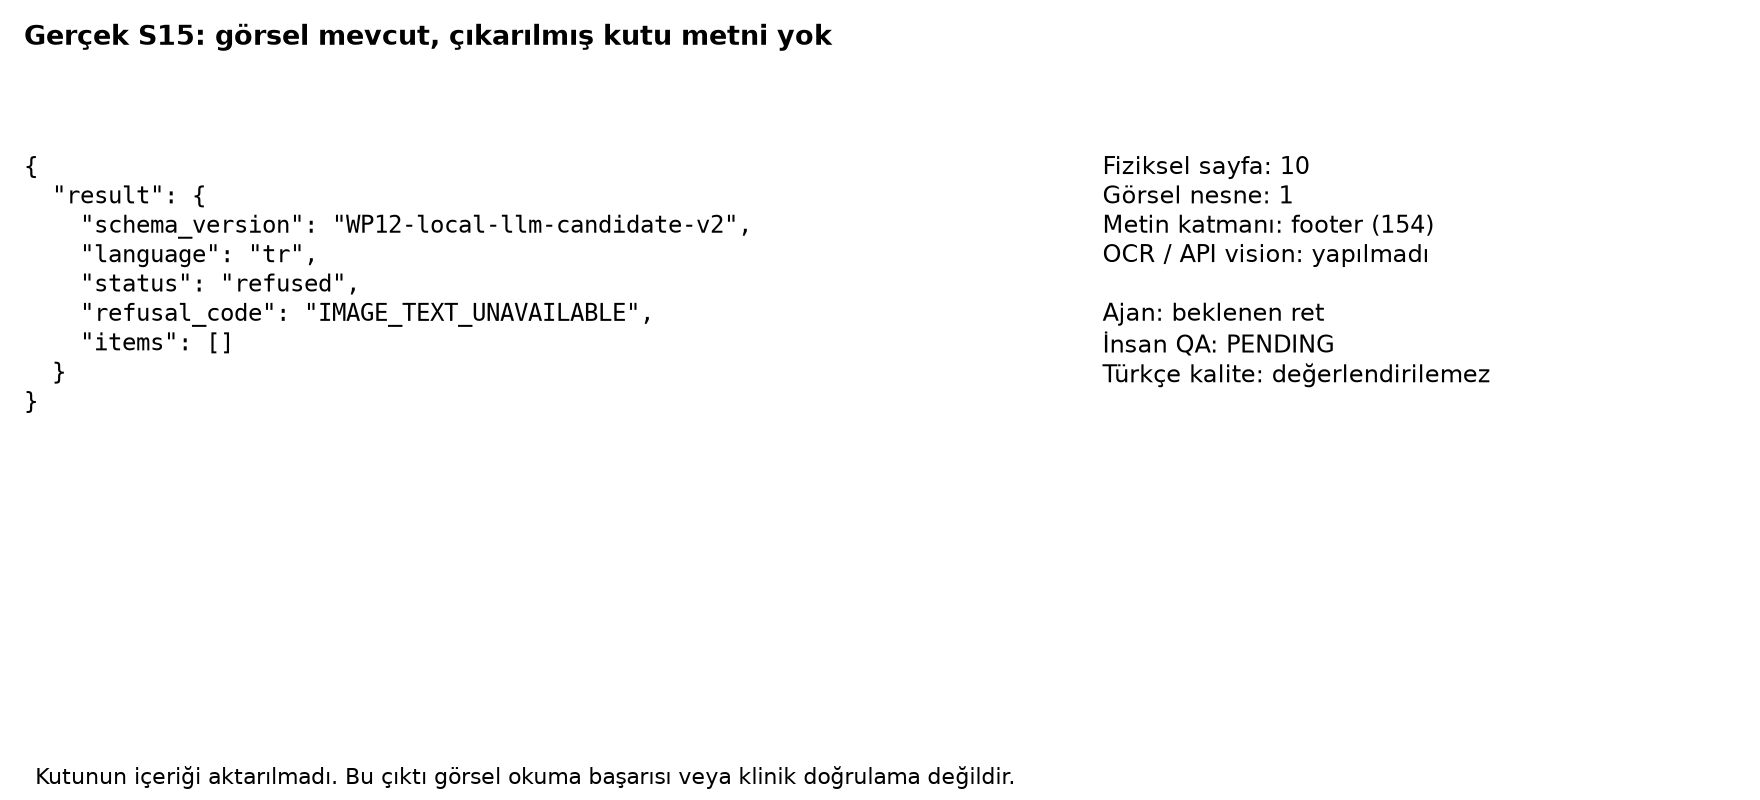

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S15_actual_review_v1'
F=ROOT/'reports/figures/WP12/openai_five_case_pilot_v1'
read=lambda n:json.loads((Q/n).read_text(encoding='utf-8'))
v=read('independent_review.json')
print('Gerçek S15, değiştirilmeden:\n'+(Q/'exact_model_message.txt').read_text(encoding='utf-8'))
display(pd.DataFrame([v['evidence_availability']]).T)
from IPython.display import Image
display(Image(filename=str(F/'02_S15_actual_refusal.png')))


**S15 yorumu:** Beklenen IMAGE_TEXT_UNAVAILABLE/boş items. NO_SOURCE kullanılmamış; belge/sayfa/görsel mevcut, kutu metni yoktur. Sistem bu koşulu açıkça bildirir; API’ye görsel gönderilmez. Bu nedenle vision yeteneği veya genel halüsinasyon dayanıklılığı sonucu çıkarılmaz. Boş ret Türkçe anlatım başarısı değildir.

,scenario,execution,model,schema,application,agent_source_review_tr,Turkish_quality_tr,formal_human_review,input_tokens,cached_tokens,output_tokens,reasoning_tokens,total_tokens,usage_token_cost_USD,review_ref
0,S01,COMPLETED,gpt-5.4-mini-2026-03-17,PASS,PASS,Kaynak uyumlu kimlik aktarımı; bazı ayrıntılar eksik,Türkçe; ayrıntı eksikleri,PENDING,1236,0,217,0,1453,0.001904,reports\qa\WP12\openai_S01_success_review_v1\independent_review.json
1,S07,COMPLETED,gpt-5.4-mini-2026-03-17,PASS,PASS,İstisna anlamı korunmuş; çevrilmemiş renal koşul/item2 atıf notu,Tam Türkçe başarısı verilmedi,PENDING,1962,0,504,0,2466,0.003740,reports\qa\WP12\openai_S07_actual_review_v1\independent_review.json
2,S04,COMPLETED,gpt-5.4-mini-2026-03-17,PASS,PASS,Bilinmeyen sıklık korunmuş; erken/usually/dilbilgisi kusurları,Türkçe; terim ve dilbilgisi notları,PENDING,2828,0,776,0,3604,0.005613,reports\qa\WP12\openai_S04_actual_review_v1\independent_review.json
3,S16,COMPLETED,gpt-5.4-mini-2026-03-17,PASS,PASS,"Beklenen NO_SOURCE, boş items; yönlendirilmiş ret",NOT_EVALUABLE_NO_EXPLANATION_TEXT,PENDING,589,0,50,0,639,0.000667,reports\qa\WP12\openai_S16_actual_review_v1\independent_review.json
4,S15,COMPLETED,gpt-5.4-mini-2026-03-17,PASS,PASS,"Beklenen IMAGE_TEXT_UNAVAILABLE, boş items; vision testi değil",NOT_EVALUABLE_NO_EXPLANATION_TEXT,PENDING,766,0,52,0,818,0.000808,reports\qa\WP12\openai_S15_actual_review_v1\independent_review.json


,scenario,item,physical_page,primary_quote_id,source_quote_exact,model_explanation_exact,agent_source_status,agent_note_tr,Turkish_review,citation_scope,uncertainty_exception,human_decision,automatic_release,prior_table_ref
0,S01,1.0,1.0,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n",İlacın adı Erythromycin Tablets BP 250 mg’dir ve etkin madde eritromisindir.,SUPPORTED_PENDING_HUMAN,Tam ürün adı ve etkin madde kaynakta mevcut; macrolide sınıfı aktarılmamış.,Kaynak uyumlu Türkçe; ayrıntı eksikleri,Mevcut birincil kaynak,Uygulanmaz: ürün kimliği,PENDING,False,reports\qa\WP12\openai_S01_success_review_v1\source_claim_comparison.csv
1,S01,2.0,6.0,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n","Erythromycin Tablets kırmızı renkli, yuvarlak, bikonveks ve enterik kaplı tabletlerdir.",SUPPORTED_PENDING_HUMAN,Kırmızı/yuvarlak/bikonveks/enterik kaplı özellikler kaynakta birebir; ambalaj adetleri aktarılmamış.,Kaynak uyumlu Türkçe; ayrıntı eksikleri,Mevcut birincil kaynak,Uygulanmaz: ürün kimliği,PENDING,False,reports\qa\WP12\openai_S01_success_review_v1\source_claim_comparison.csv
2,S07,1.0,7.0,quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,"Bu başlık, tetracyclines sınıfı için renal toksisite bağlamını verir: BUN artışı bildirilmiştir ve bunun dozla ilişkili olabileceği söylenir. Bu ifade sınıf düzeyindedir; tek başına doxycycline için bağımsız doğrudan kanıt olarak okunmamalıdır.",CORE_SUPPORTED_WITH_LANGUAGE_NOTE,tetracyclines sınıf adı İngilizce bırakılmış. BUN bildirimi ve dozla ilişkili olabileceği ifadesi sınıf kapsamında; doğrudan doxycycline kanıtı olmadığı belirtilmiş.,Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
3,S07,2.0,7.0,quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48,The following adverse reactions have been observed in patients receiving tetracyclines. \n,"Sınıf girişine göre sonraki advers reaksiyonlar tetracyclines alan hastalarda gözlenmiştir; bu, alt başlıktaki renal ifadenin sınıf bağlamında anlaşılması gerektiğini gösterir. Bu nedenle kayıt, tetracycline sınıfını doğrudan doxycycline'e eşitlemeden okunmalıdır.",CORE_CLASS_INTRO_SUPPORTED_CITATION_CONTEXT_NOTE,"İlk sınıf gözlemi doğrudan alıntıyla destekli. Renal alt başlık/doxycycline yorumu tüm girdi bağlamında destekleniyor; yalnız cite edilen sınıf-giriş cümlesi bu sözcükleri içermiyor. Bu, mevcut teknik kuralı değiştiren bir FAIL değildir; item düzeyinde atıf ayrıntısı için ajan inceleme notudur.",Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
4,S07,3.0,4.0,quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b,The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indicate that this does not occur \nwith the use of doxycycline in patients with impaired renal function. \n,"Tetracyclines’in antianabolik etkisi BUN artışına yol açabilir. Mevcut çalışmalara göre bu durum, impaired renal f

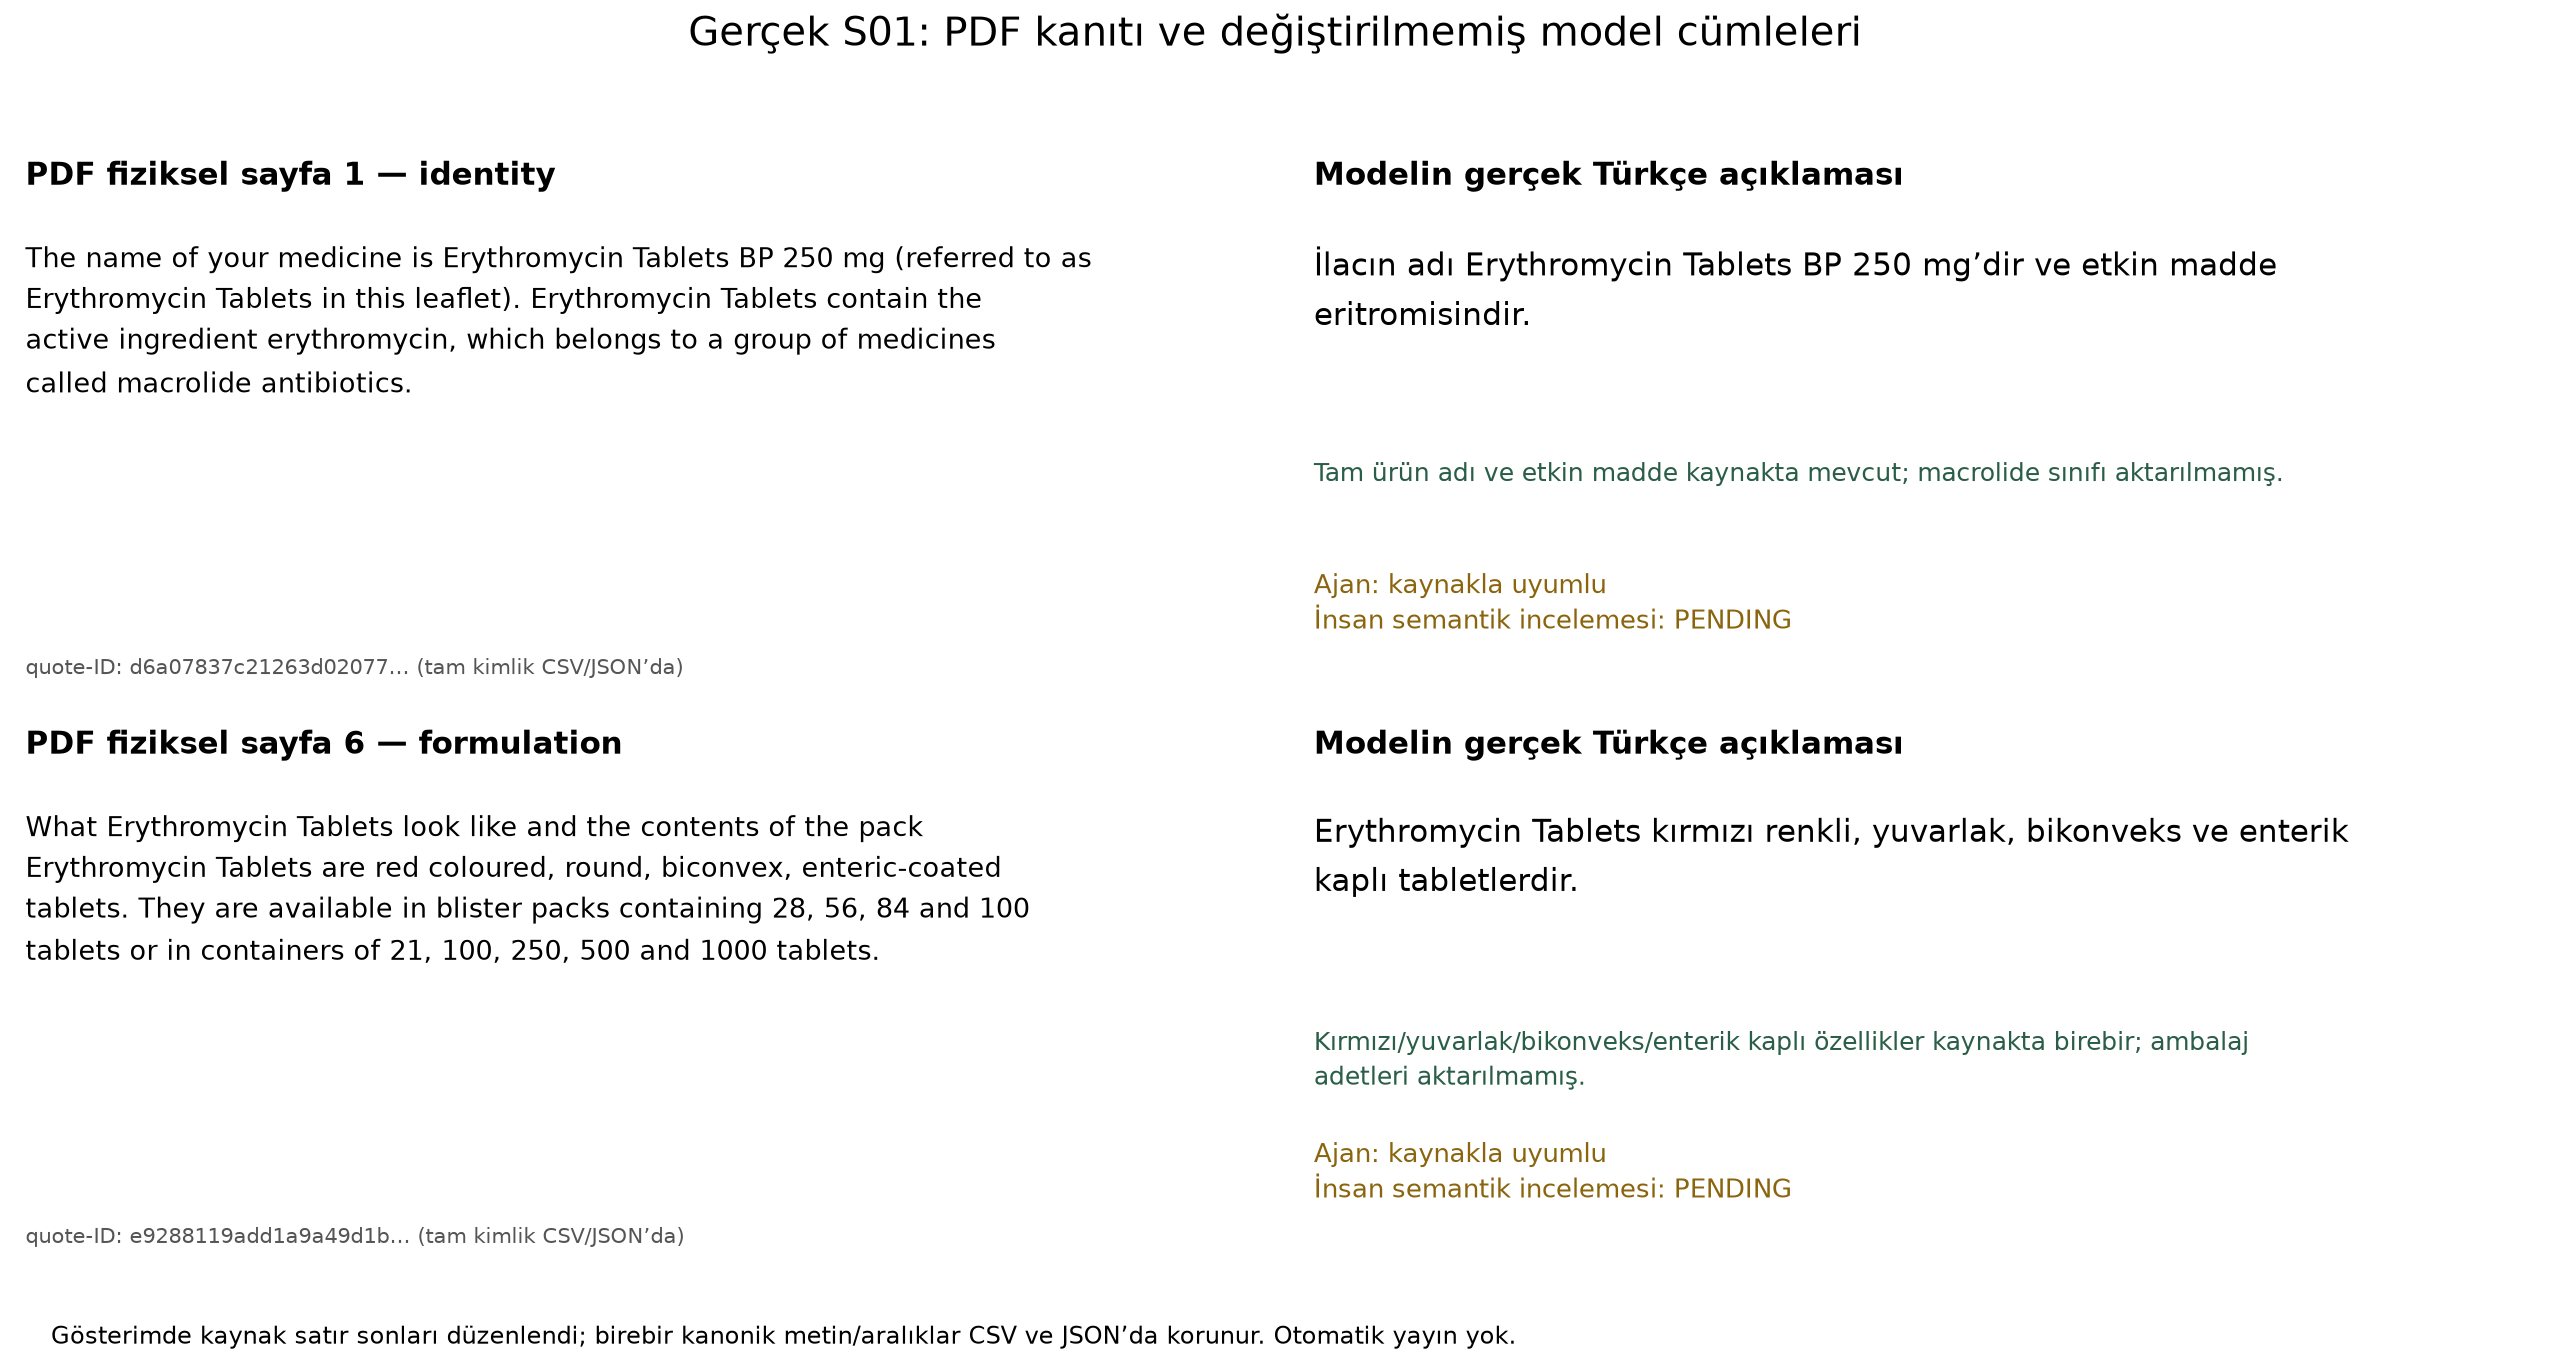

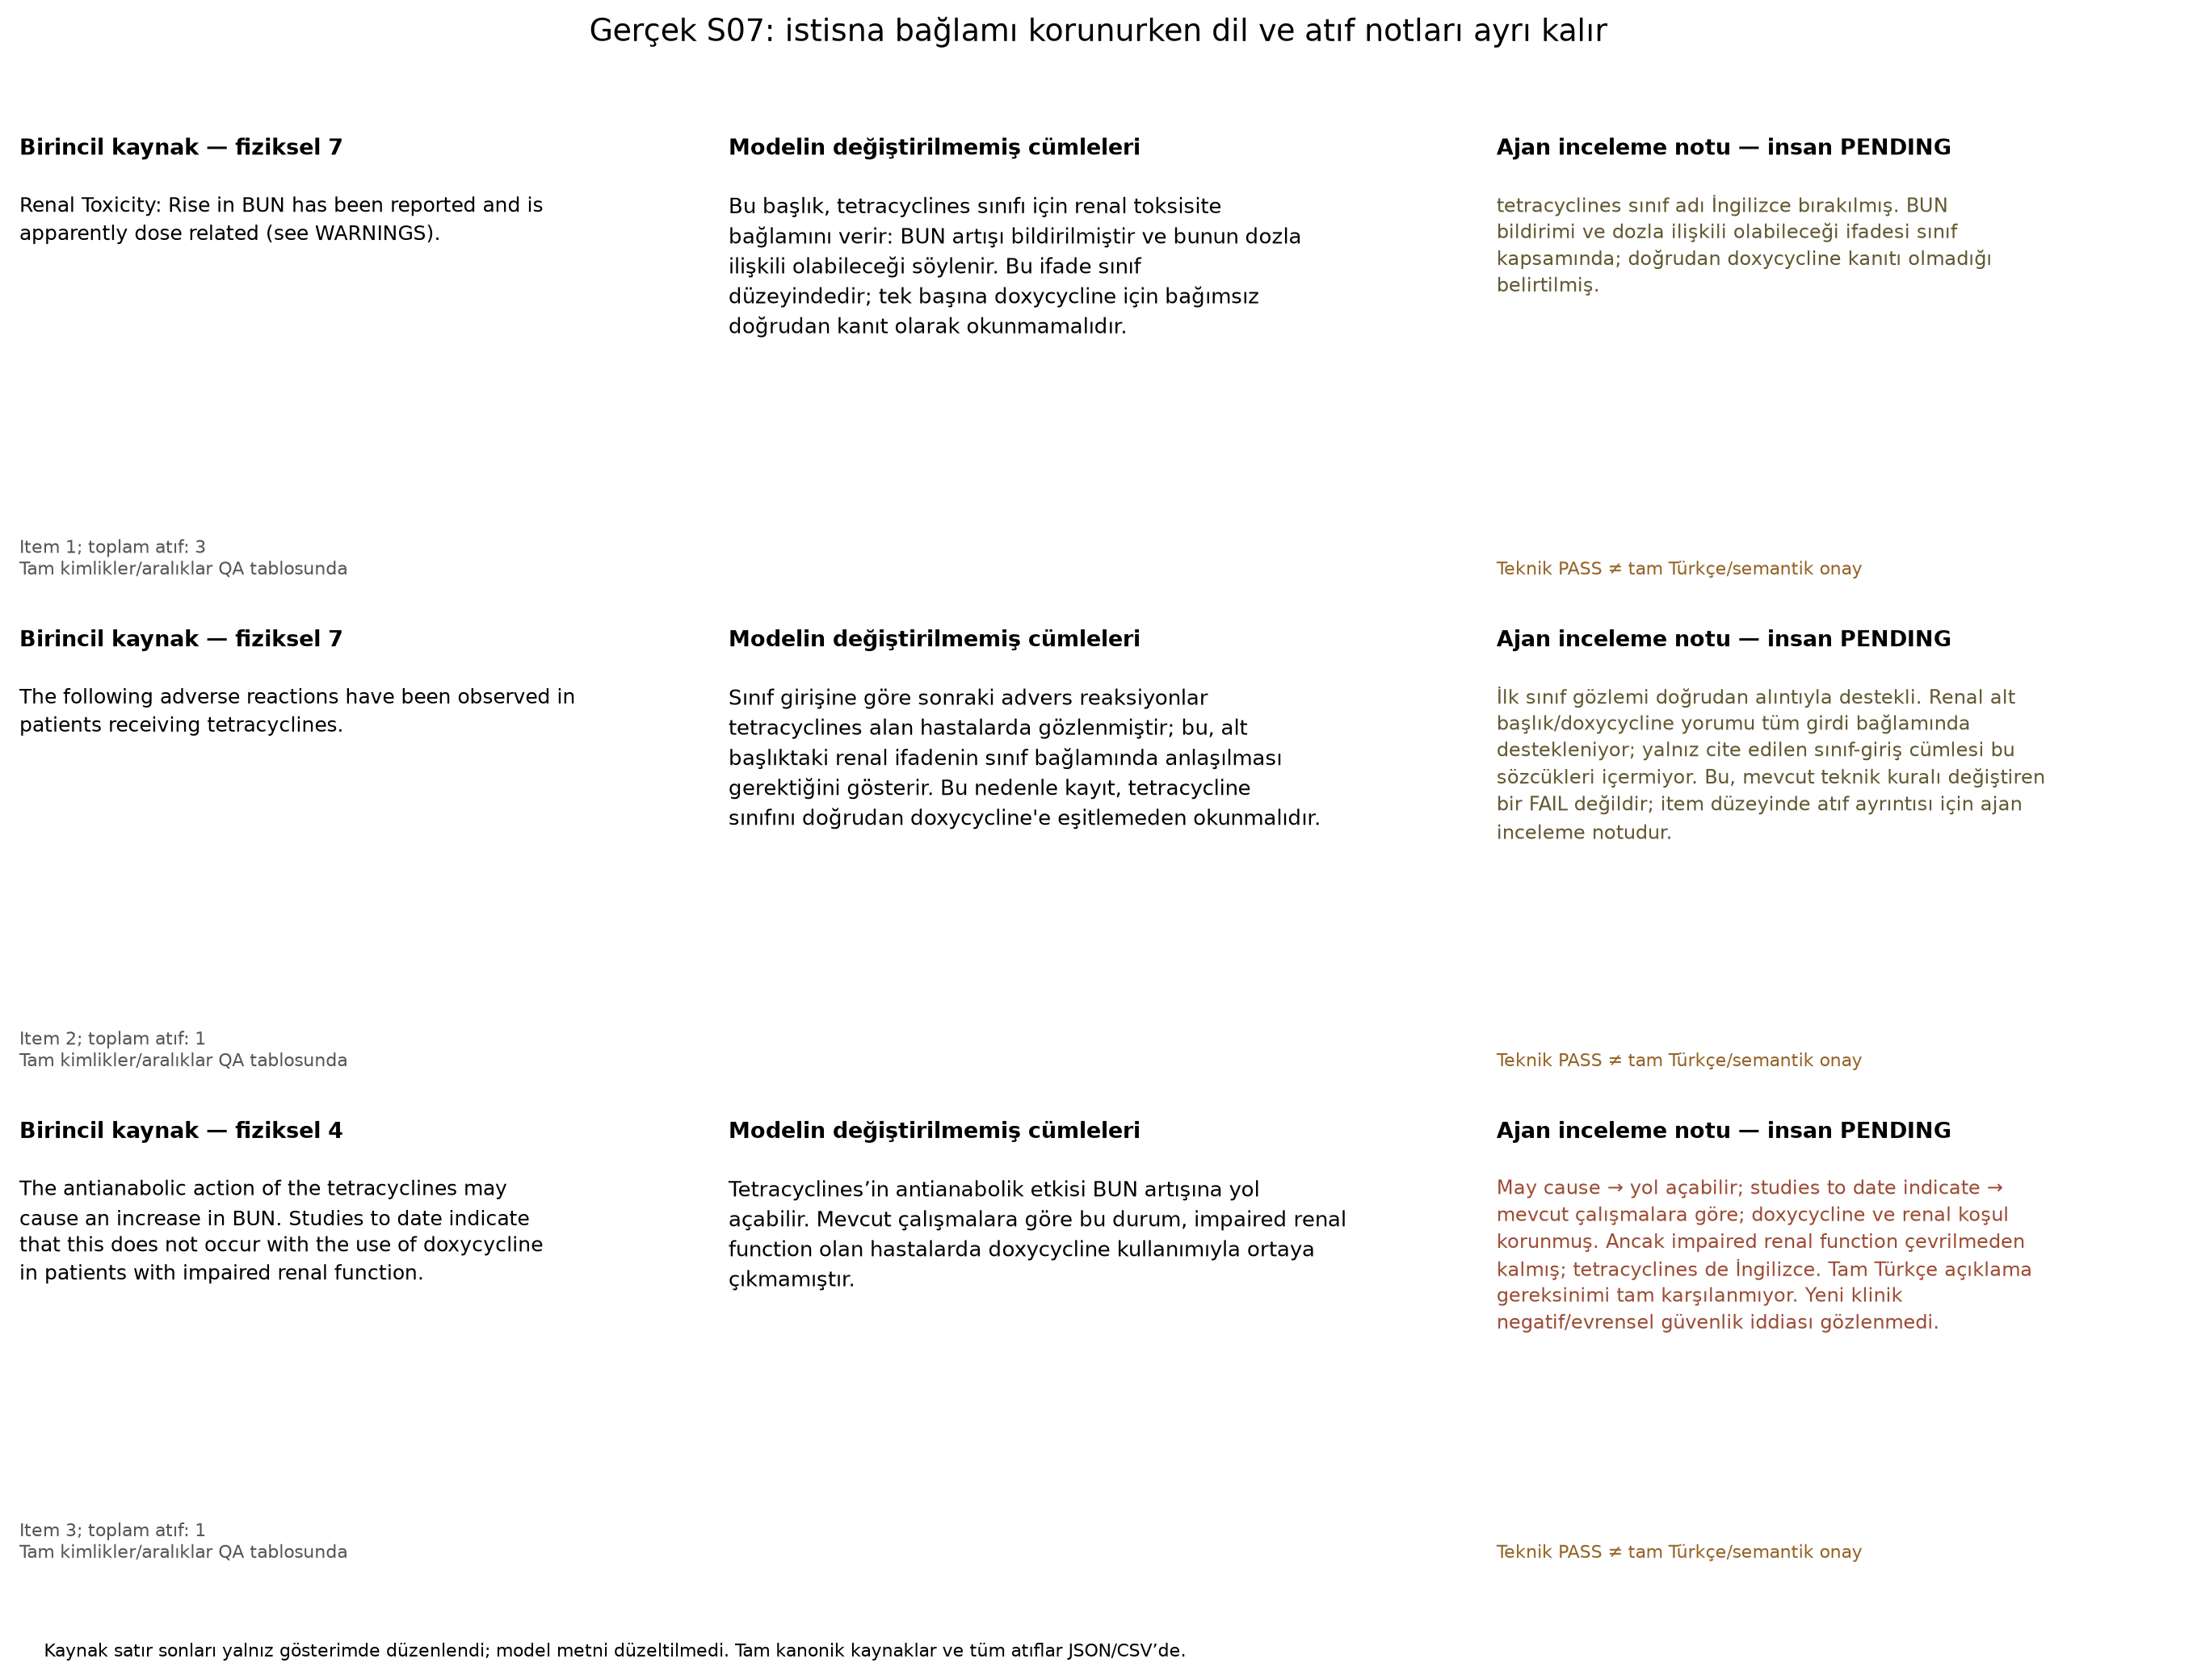

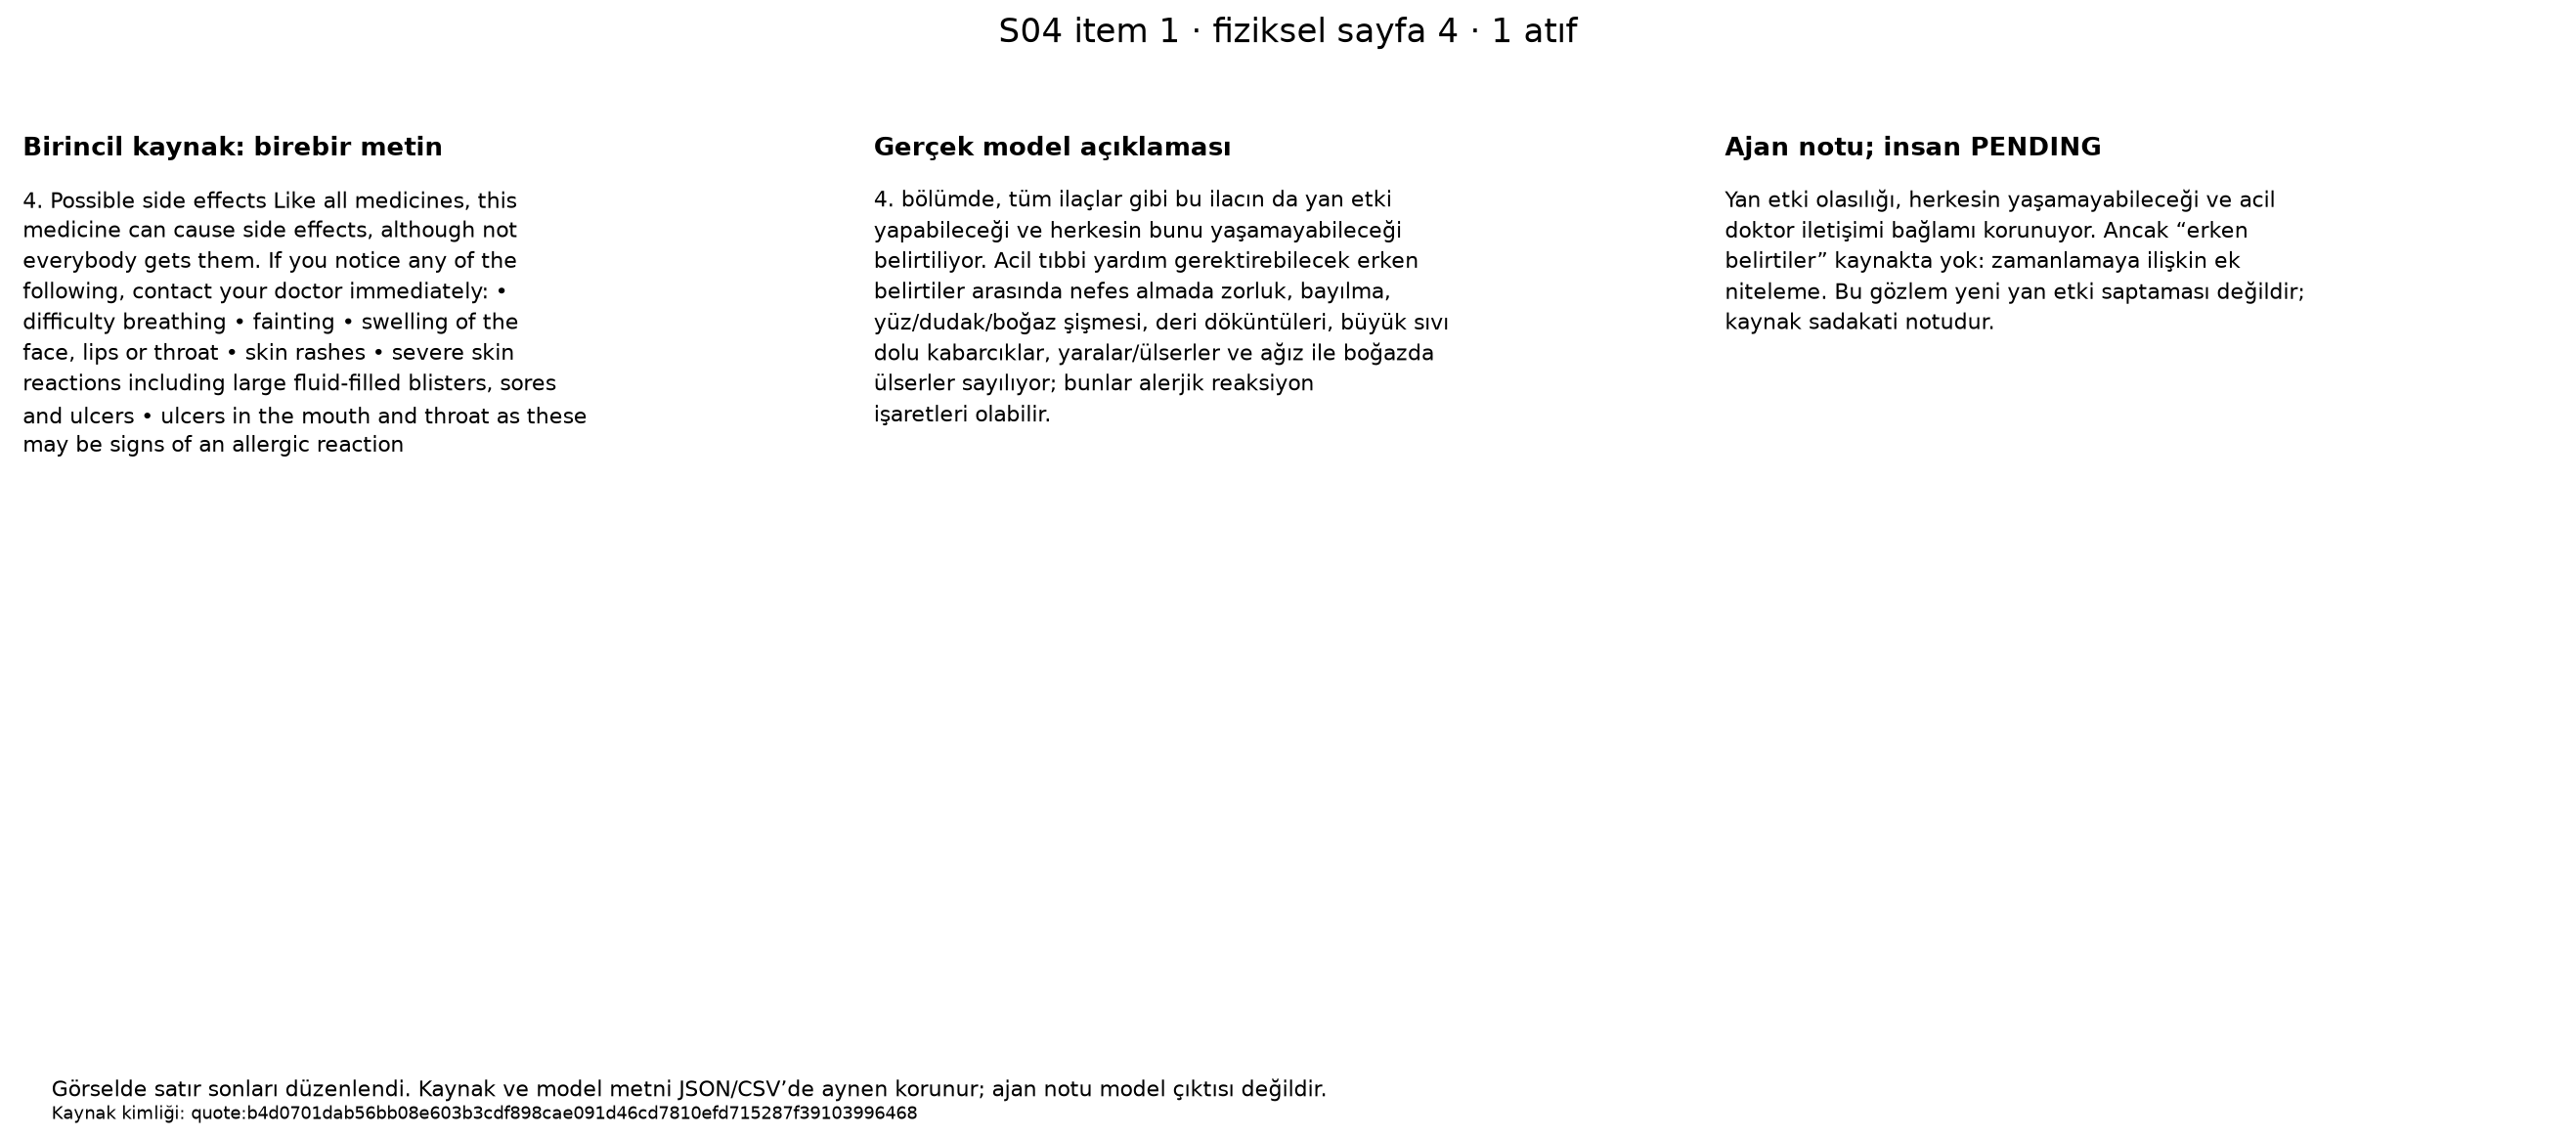

In [2]:

s=pd.read_csv(Q/'five_case_scientific_summary.csv');display(s)
t=pd.read_csv(Q/'five_case_source_claim_comparison.csv')
with pd.option_context('display.max_colwidth',None):display(t)
for path in ['openai_S01_success_review_v1/01_PDF_vs_real_claims.png','openai_S07_actual_review_v1/01_real_quotes_claims_and_flags.png','openai_S04_actual_review_v1/01_real_source_and_explanation.png']:
 display(Image(filename=str(ROOT/'reports/figures/WP12'/path)))


**Kaynak/dil yorumu:** S01 destekli kimlik aktarımıyla birlikte eksik ayrıntı içerir. S07’de istisna anlamı yanında çevrilmeyen impaired renal function ve atıf kapsamı sorunu vardır. S04’te bilinmeyen sıklık korunur, ancak kaynakta olmayan erken, serbest usually aktarımı ve dilbilgisi kusuru vardır. Retler açıklama kalitesiyle birleştirilmez; hiçbirine kusursuz insan onayı yazılmaz. Gerçek kaynaklar/yanıtlar değiştirilmeden tabloda ve eski görsellerde gösterilir.

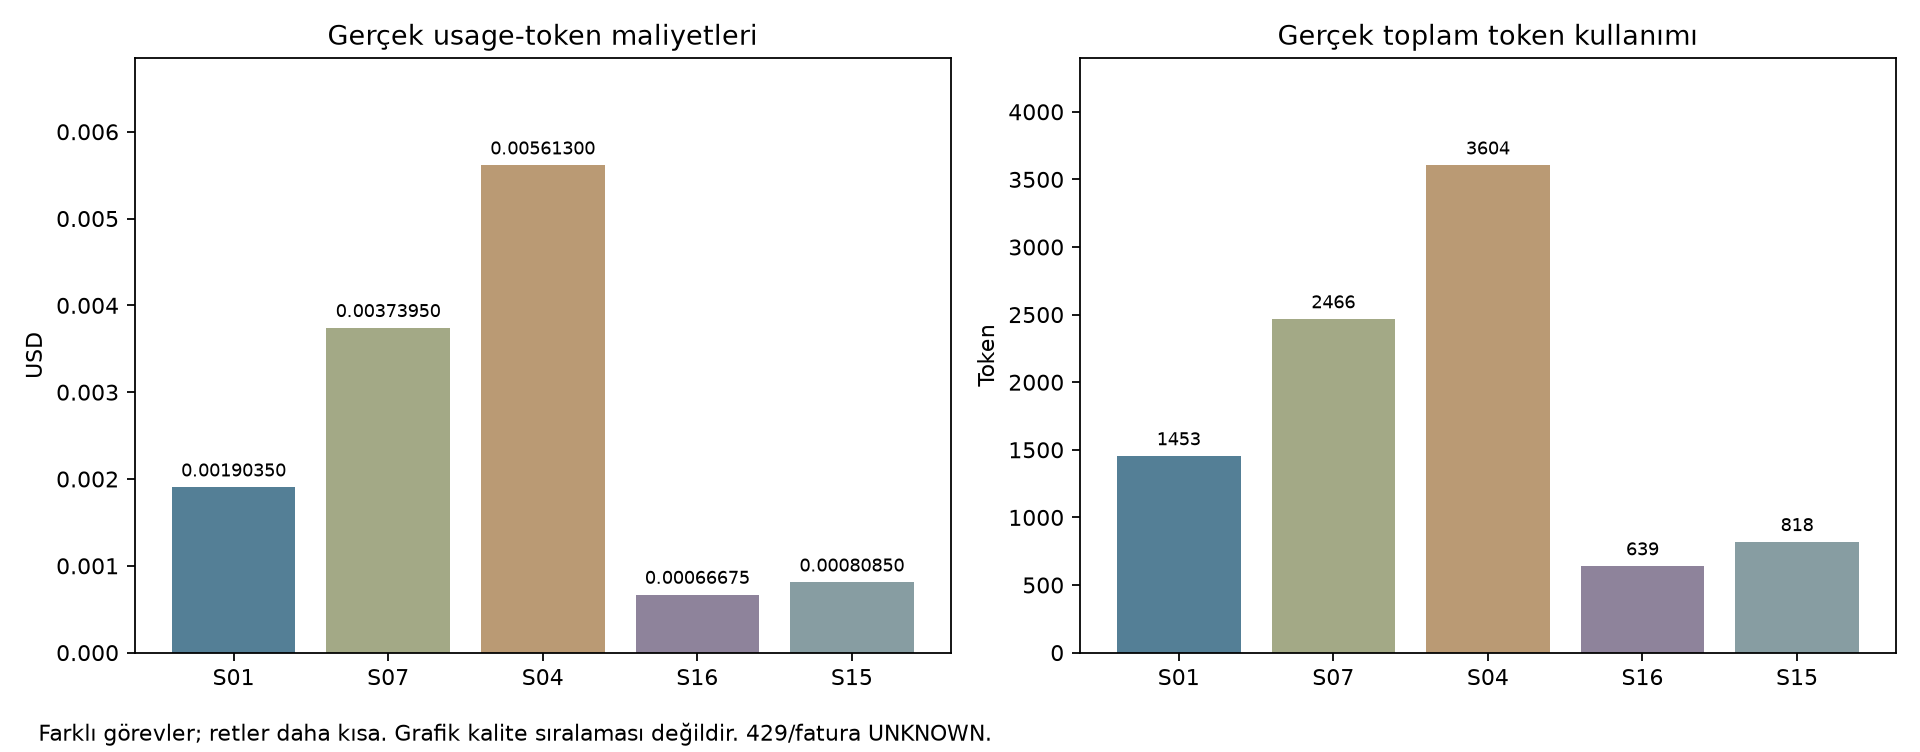

,bilinen_completed_alt_toplam_USD,kesin_fatura,HTTP_reservations_total,inference_reservations_total,reserved_USD,within_limits,unknown_prior_cost_not_refunded,actual_invoice_total
0,0.01273125,UNKNOWN_PRIOR_429_USAGE_AND_BILLING_NOT_QUERIED,18,6,0.138,True,True,UNKNOWN_NOT_QUERIED


,model_method,experiment_status,pipeline_terminal_status,independent_content_schema_status,actual_language_agent,source_faithfulness_agent,human_review,actual_server_prompt_tokens,output_tokens,server_total_seconds,raw_response_ref,raw_response_sha256,scenario,formal_human_review,user_positive_statement,preflight_count_only,usage_token_cost_USD,HTTP_latency_seconds,latency_definition,citation_note
0,Gemma V1,FAIL,SCHEMA_OR_SOURCE_VALIDATION_FAILED,PASS,FAIL_ENGLISH,FAIL_CONTRADICTED,PENDING,919.0,188.0,8.708088,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\experim...,8ad96fef1e68c9beb826a3ca343d44104bd4069d4002768122f04f127449e3b2,S01,PENDING,NaN,NaN,NaN,NaN,NaN,NaN
1,Gemma V2,FAIL,TOKEN_COUNT_ALIGNMENT_FAILED,PASS,FAIL_ENGLISH,CORE_SUPPORTED_OMISSIONS,PENDING,729.0,312.0,8.157021,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\gemma_v...,5921534f455a1e5fcc9f3a105a5de4cd15575fce8bb671f9a60a6842c0523638,S01,PENDING,NaN,NaN,NaN,NaN,NaN,NaN
2,Qwen3 4B,NOT_RUN,BLOCKED_HOST_RAM_AND_TOKEN_API_PREREQUISITES,NOT_RUN,NOT_RUN,NOT_RUN,PENDING,NaN,NaN,NaN,NaN,NaN,S01,PENDING,NaN,NaN,NaN,NaN,NaN,NaN
3,OpenAI / first account,API_BILLING_BLOCKED_NO_MODEL_OUTPUT,HTTP429 credit_balance_exhausted,NOT_EVALUABLE,NOT_EVALUABLE,NOT_EVALUABLE,PENDING_NO_OUTPUT,NaN,NaN,NaN,NaN,NaN,S01,PENDING,NaN,1236.0,NaN,NaN,NaN,NaN
4,gpt-5.4-mini-2026-03-17 / corrected account,COMPLETED_PENDING_HUMAN,HTTP200 completed,PASS,TURKISH_SUPPORTED_SOURCE_PROPER_NAMES_RETAINED,SUPPORTED_FOR_TWO_RETURNED_ITEMS,PENDING,1236.0,217.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,57915e6d706b4ba88afcada79518454a30b6ccd215912b14e2d95e9e24c6a16d,S01,PENDING,SEPARATE_RECEIPT_FOR_TWO_ITEMS,NaN,0.001904,3.953,HTTP client wall duration; local Gemma server-duration is a different measure,NaN
5,gpt-5.4-mini-2026-03-17,COMPLETED_WITH_AGENT_QUALITY_FLAGS,HTTP200 completed / technical PASS,NaN,NOT_FULL_PASS_UNTRANSLATED_CRITICAL_CONDITION,CLASS_SCOPE_AND_BOTH_EXCEPTION_CLAUSES_RETAINED_WITH_NOTES,PENDING,1962.0,504.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,6586f01ecf0160bbf0a30638897d2c9b81af7cf2bf307f5c38a82137b07ac904,S07,PENDING,NaN,NaN,0.003740,4.813,NaN,ITEM2_CONTEXT_REFERENCE_REVIEW_NOTE_NOT_SCHEMA_FAILURE
6,gpt-5.4-mini-2026-03-17,COMPLETED_WITH_AGENT_REVIEW_NOTES,HTTP200 completed / technical PASS,NaN,TURKISH_EXPLANATION_WITH_QUOTED_ENGLISH_MEDICAL_TERMS_AND_STYLE_NOTES,UNKNOWN_FREQUENCY_AND_PAGE4_CONTEXT_RETAINED_WITH_QUALIFIER_NOTES,PENDING,2828.0,776.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,acbafb53ffb8c937d5d1589a979d165b35ae654f94263b424653443b9edc6138,S04,PENDING,NaN,NaN,0.005613,5.203,NaN,NaN
7,gpt-5.4-mini-2026-03-17,COMPLETED_EXPECTED_REFUSAL_AGENT_PENDING_HUMAN,HTTP200 completed / schema and application PASS,NaN,NOT_EVALUABLE_NO_EXPLANATION_TEXT,EXPECTED_NO_SOURCE_REFUSAL_NO_GENERATED_CLAIMS_IN_THIS_RESPONSE,NaN,589.0,50.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,776cebb1d7f73e54e07d7127876b7b11191405ce1abf94ff3e8b599323f8f15b,S16,PENDING,NaN,NaN,0.000667,2.047,NaN,NaN
8,gpt-5.4-mini-2026-03-17,COMPLETED_EXPECTED_IMAGE_TEXT_REFUSAL_AGENT_PENDING_HUMAN,HTTP200 completed / schema and application PASS,NaN,NOT_EVALUABLE_NO_EXPLANATION_TEXT,EXPECTED_IMAGE_TEXT_UNAVAILABLE_REFUSAL_NO_GENERATED_CLAIMS_IN_THIS_RESPONSE,NaN,766.0,52.0,NaN,C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\qa\WP12\openai_...,95cbfa72e092e1bcdb0e85cab071a227e30cd196451a6a78720cc0bfe8f20350,S15,PENDING,NaN,NaN,0.000808,1.328,NaN,NaN


,teknik_kontrol,sonuç
0,raw_manifest_and_inventory,True
1,raw_response_hash,True
2,frozen_request_and_no_source_payload,True
3,prompt_and_execution_hash,True
4,raw_JSON_and_recomputed_assessment,True
5,schema_and_application,True
6,expected_refusal_no_claims,True
7,completed_model_and_IDs,True
8,single_inference_three_HTTP200,True
9,exact_token_count_and_limits,True


,tests,returncode,API_requests
0,10,0,0


In [3]:

display(Image(filename=str(F/'01_five_actual_usage_costs.png')))
display(pd.DataFrame([{'bilinen_completed_alt_toplam_USD':v['known_completed_five_case_token_cost_USD'],'kesin_fatura':v['invoice_total'],**v['aggregate_budget']}]))
display(pd.read_csv(Q/'all_real_runs_comparison.csv').drop(columns=['model_message_exact'],errors='ignore'))
display(pd.DataFrame({'teknik_kontrol':list(v['checks']),'sonuç':list(v['checks'].values())}))
display(pd.DataFrame([read('test_summary.json')]))


**Bilimsel sınır:** Beş tamamlanmış bulut yanıtında schema/application geçişi gözlenmiştir; semantik doğruluk oranı hesaplanmaz. Önceki429 ve GemmaFAIL/QwenNOT_RUN ayrı kalır. Seçilmiş ve farklı yöntem/sorular eş görevli model benchmark’ı değildir. S01 üzerinde yöntem geliştirme geçmişi vardır; ret yönergeleri açıktır. Diğer14frozen senaryo bu bulut pilotunda NOT_RUN. Formal insanPENDING; kullanım alt toplamı fatura/bakiye değildir.18HTTP/6inference/.138USD rezerv;30/10/.25 tavan korunur. WP12 nihai kapanışı ve WP13 uygulaması kullanıcı kararını bekler.